In [1]:
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from ddpm.data.das_dataset import DasDataset
from ddpm.diffusion.rad_noise_scheduler import RADNoiseScheduler
from ddpm.models.unet_rad import RAD
from ddpm.diffusion.rad_inpainting_scaled import inpaint_scaled

device="cuda" if torch.cuda.is_available() else "cpu"

das_data=Path("/datasets/training/earthquake/share/SISSLE_south30")
checkpoints=Path("checkpoints")

scheduler_rad=RADNoiseScheduler(ph1_steps=1000,ph2_steps=1000,beta_start=1e-4,beta_end=0.02,device=device)

with open(checkpoints/"data_scaling.json") as f: scaling=json.load(f)
data_scale=scaling["data_scale"]
print("data_scale:",data_scale)

print("available files:",sorted(p.name for p in das_data.glob("*.h5")))

data_scale: 2.023162409488313
available files: ['test_1000.h5', 'test_1001.h5', 'test_1010.h5', 'test_1011.h5', 'test_1100.h5', 'test_1101.h5', 'test_1110.h5', 'test_1111.h5', 'train_1000.h5', 'train_1001.h5', 'train_1010.h5', 'train_1011.h5', 'train_1100.h5', 'train_1101.h5', 'train_1110.h5', 'train_1111.h5']


In [28]:
def load_model(path,key):
    m=RAD(in_channels=1,out_channels=1,base_channels=64,channels_multiplier=(1,1,2,2,4),nbr_rb=2,dropout=0.1).to(device)
    m.load_state_dict(torch.load(path,map_location=device)[key])
    m.eval()
    return m

model_v1=load_model(checkpoints/"das_rad_earthquake_model.pth","model_rad")         # v1: no EMA
model_v2=load_model(checkpoints/"das_rad_earthquake_model_v2.pth","ema_model_rad")  # v2: EMA
model_v3=load_model(checkpoints/"das_rad_earthquake_model_v3.pth","ema_model_rad")  # v3: EMA + scaling

models=[("v1",model_v1,1.0),("v2 EMA",model_v2,1.0),("v3 EMA (scaled)",model_v3,data_scale)]
print("models loaded")
traffic_set=DasDataset([das_data/"test_1111.h5"])
print("traffic patches:",len(traffic_set))

models loaded
traffic patches: 128


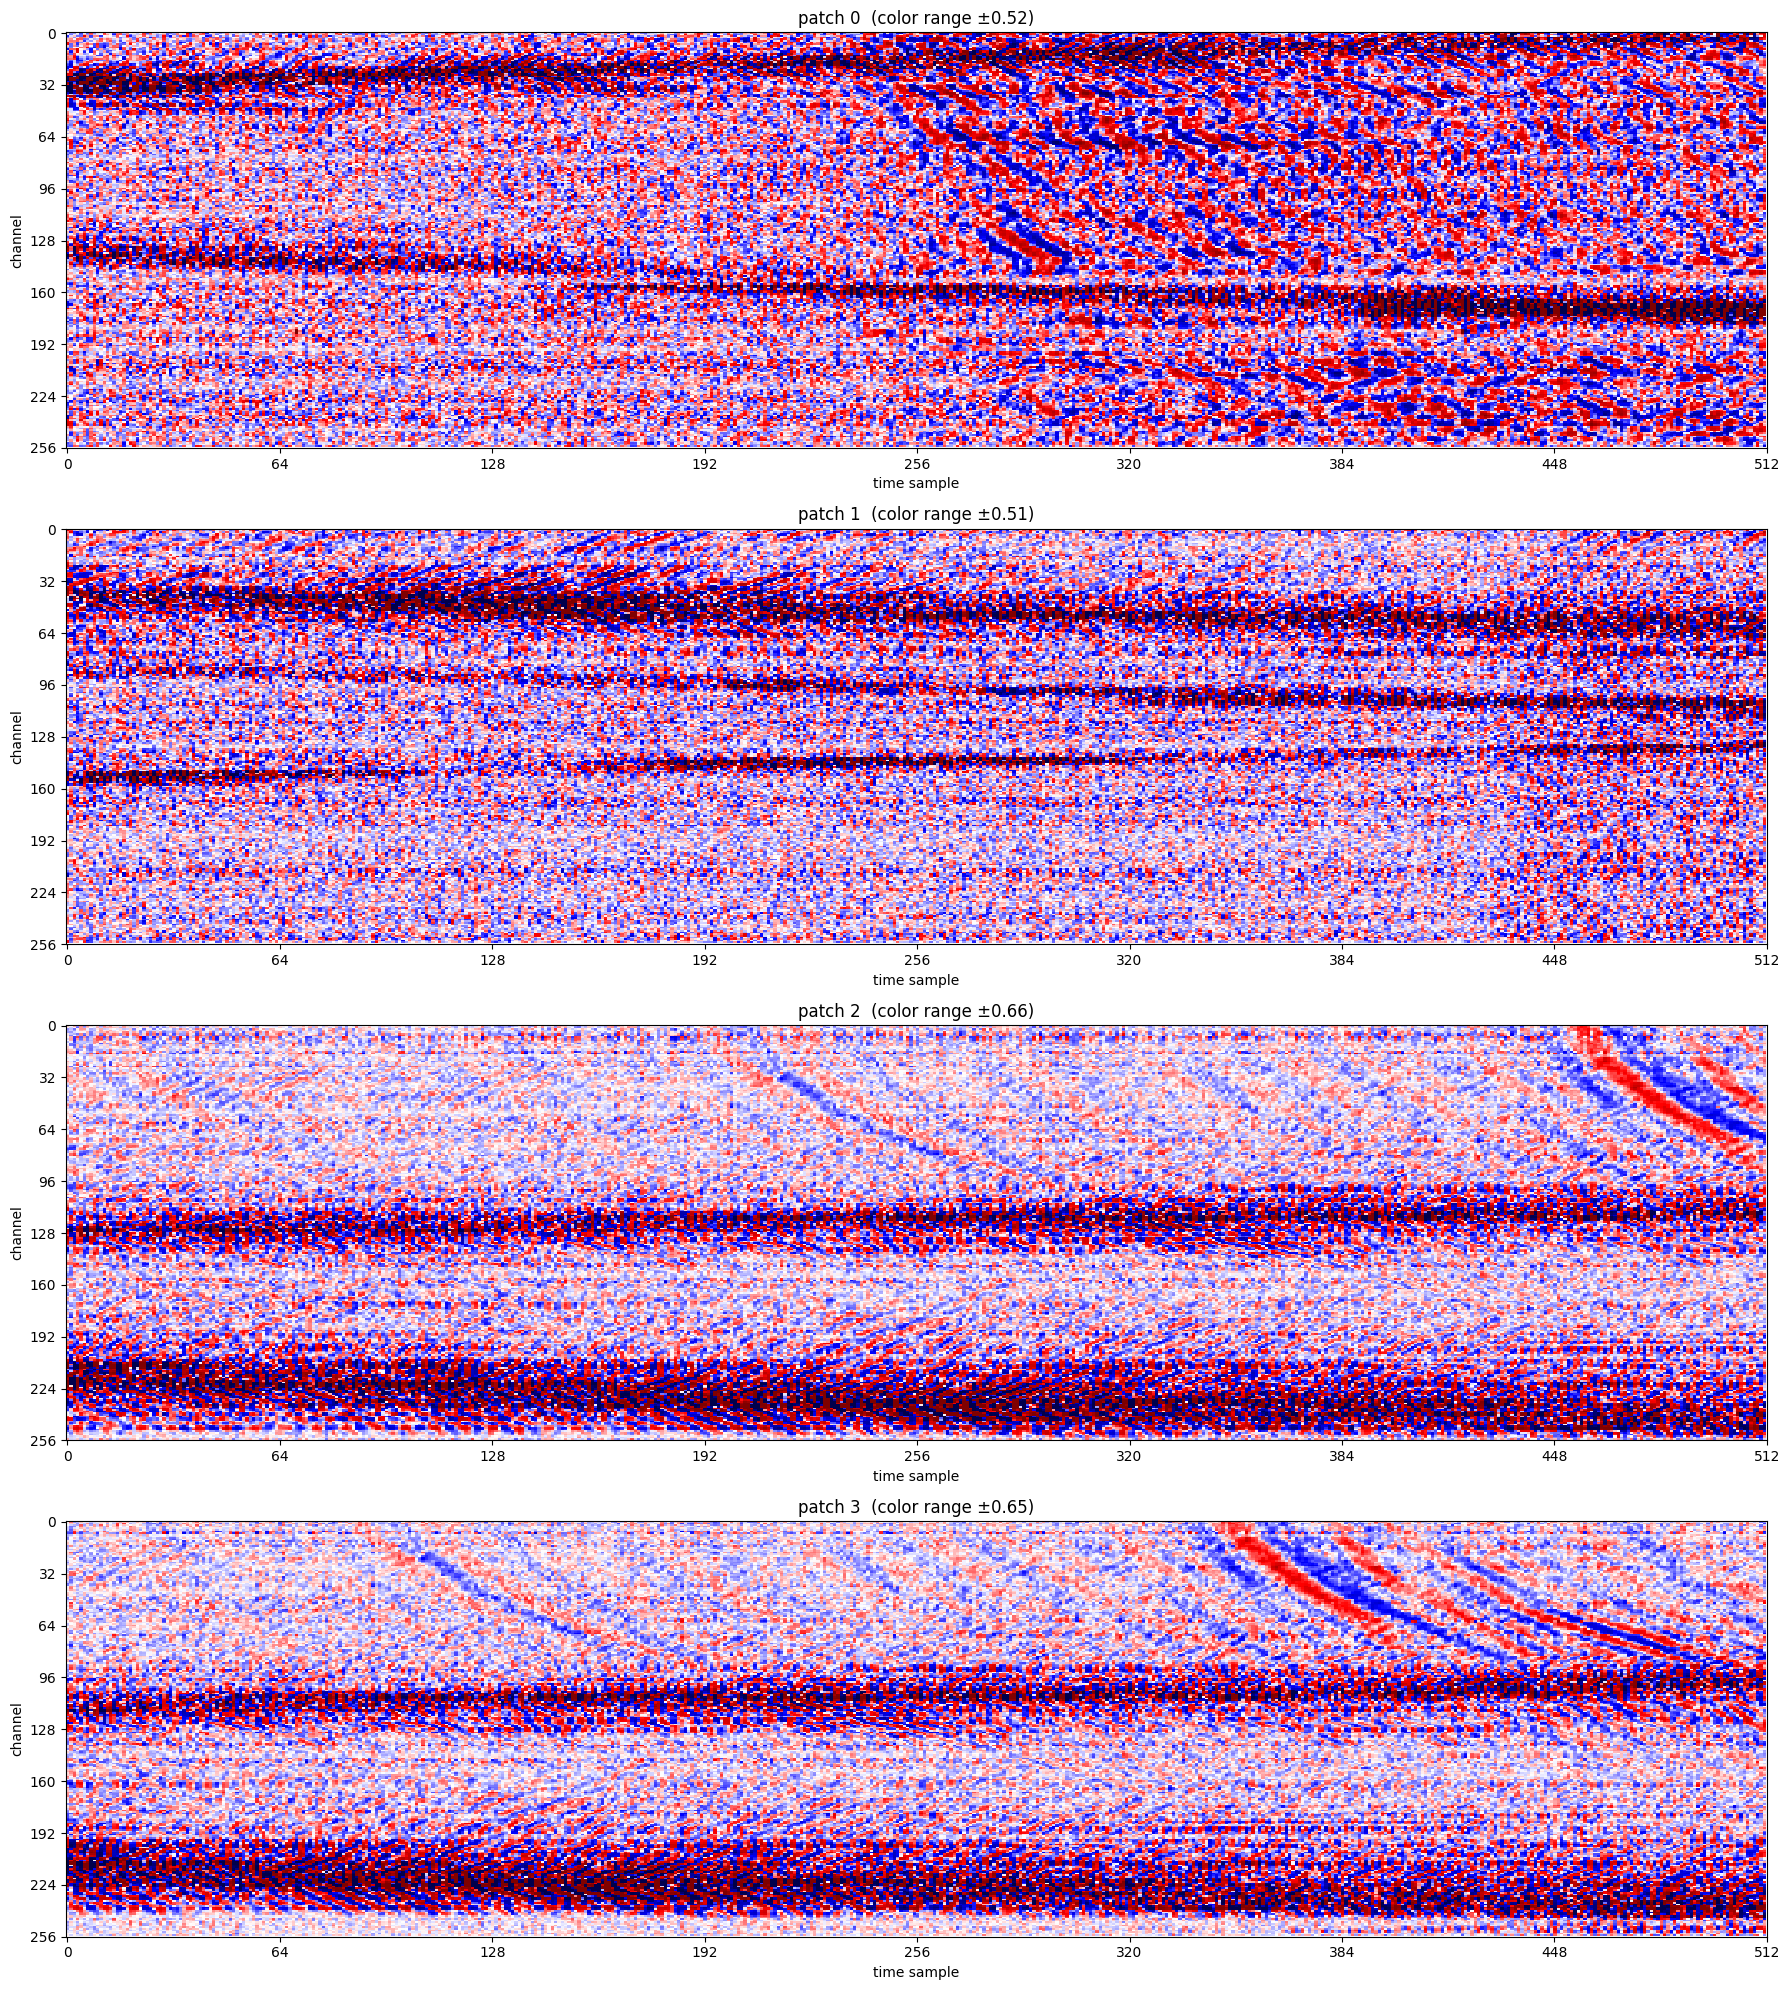

In [3]:
def show_patch(img,title="",ax=None,q=0.98):
    img=img.detach().cpu() if torch.is_tensor(img) else img
    w=float(torch.quantile(torch.as_tensor(img).abs().flatten().float(),q))   # robust color range per patch
    ax=ax or plt.gca()
    ax.imshow(img,aspect="auto",cmap="seismic",vmin=-w,vmax=w,interpolation="nearest")
    ax.set_title(f"{title}  (color range ±{w:.2f})")
    ax.set_xticks(range(0,513,64)); ax.set_yticks(range(0,257,32))
    ax.set_xlabel("time sample"); ax.set_ylabel("channel")

ids=[0,1,2,3]
fig,axes=plt.subplots(len(ids),1,figsize=(18,5*len(ids)))
for a,i in zip(axes,ids): show_patch(traffic_set[i][0],f"patch {i}",a)
plt.tight_layout(); plt.show()

In [22]:
def line_mask(H,W,segments,device, margin=64):
    """segments: list of ((t1,c1),(t2,c2),thickness) in pixels. Returns RAD mask: 1 = keep, 0 = hole."""
    yy,xx=torch.meshgrid(torch.arange(H,device=device),torch.arange(W,device=device),indexing="ij")
    hole=torch.zeros(H,W,dtype=torch.bool,device=device)
    for (t1,c1),(t2,c2),th in segments:
        dx,dy=t2-t1,c2-c1
        L2=max(dx*dx+dy*dy,1e-9)
        u=(((xx-t1)*dx+(yy-c1)*dy)/L2).clamp(0,1)
        dist=((xx-(t1+u*dx))**2+(yy-(c1+u*dy))**2).sqrt()
        hole|=dist<=(th+margin)/2
    return (~hole).float()[None]                          # [1,H,W]

def show_patch(img,title="",ax=None,w=None,q=0.98):
    img=img.detach().cpu() if torch.is_tensor(img) else torch.as_tensor(img)
    if w is None: w=float(torch.quantile(img.abs().flatten().float(),q))
    ax=ax or plt.gca()
    ax.imshow(img,aspect="auto",cmap="seismic",vmin=-w,vmax=w,interpolation="nearest")
    ax.set_title(title); ax.set_xticks(range(0,513,64)); ax.set_yticks(range(0,257,32))
    return w

In [23]:
margin=16    # extra thickness in pixels for all traffic lines; increase to widen the masks

traffic_segments={
    0:[((0,32),(256,16),18),((256,16),(512,3),16),            # upper band, slowly rising
       ((0,132),(160,148),16),((160,150),(512,168),16),       # middle band, descending
       ((370,172),(512,174),24)],                             # strong part on the right
    1:[((0,36),(160,48),24),((160,48),(512,60),22),           # upper band
       ((0,92),(256,104),14),((256,104),(512,116),16),        # middle band
       ((0,155),(256,145),14),((256,145),(512,132),14)],      # lower band
    2:[((0,124),(512,118),32),                                # band around channel 120
       ((0,222),(512,232),50)],                               # wide band at the bottom
    3:[((0,112),(512,106),26),                                # band around channel 110
       ((0,218),(512,232),52)],                               # wide band at the bottom
}

patch_ids=list(traffic_segments.keys())
X=torch.stack([traffic_set[i] for i in patch_ids]).to(device)                                       # [4,1,256,512]
M=torch.stack([line_mask(256,512,traffic_segments[i],device,margin=margin) for i in patch_ids])     # [4,1,256,512]

for i,m in zip(patch_ids,M):
    print(f"patch {i}: hole share {100*(1-m.mean().item()):.1f} %")

patch 0: hole share 25.8 %
patch 1: hole share 38.1 %
patch 2: hole share 42.8 %
patch 3: hole share 41.4 %


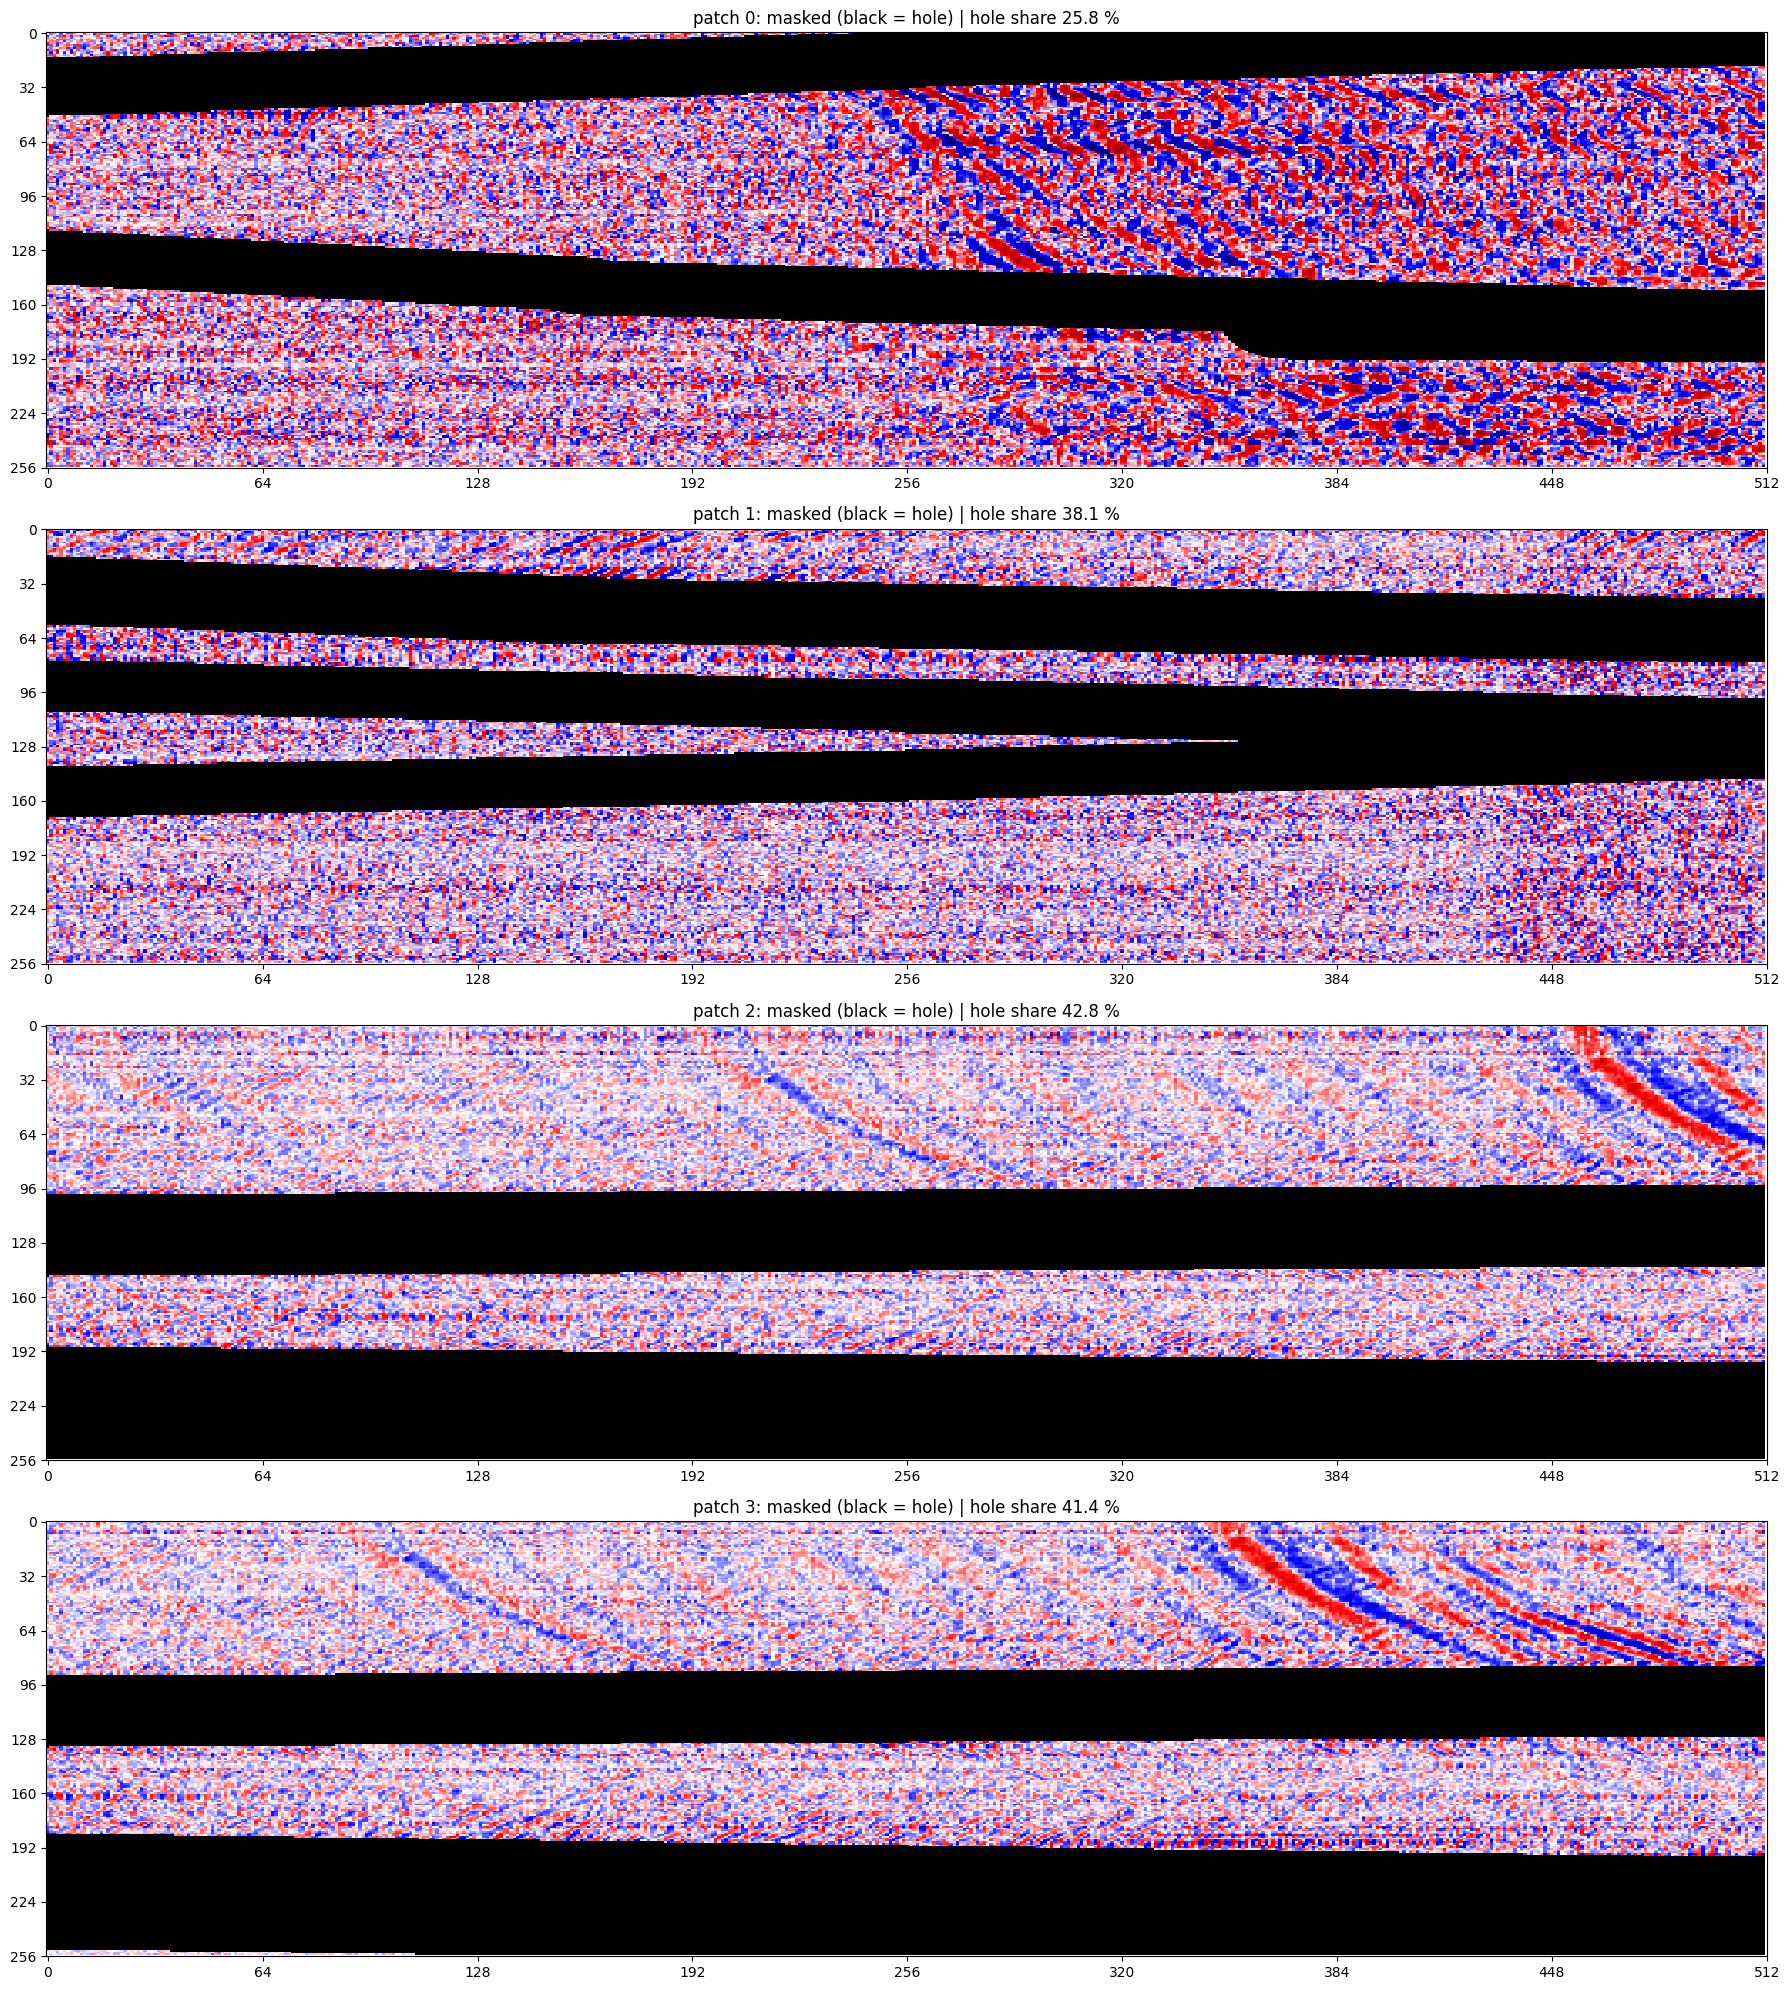

In [ ]:
fig,axes=plt.subplots(len(patch_ids),1,figsize=(18,5*len(patch_ids)))
for a,i,x,m in zip(axes,patch_ids,X,M):
    img=x[0].cpu().clone()
    img[m[0].cpu()==0]=float("nan")                     
    w=float(torch.quantile(x[0].abs().flatten().cpu(),0.98))
    cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")   
    a.imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
    a.set_title(f"patch {i}: masked (black = hole) | hole share {100*(1-m.mean().item()):.1f} %")
    a.set_xticks(range(0,513,64)); a.set_yticks(range(0,257,32))
plt.tight_layout(); plt.show()

In [25]:
results={}
for name,model,scale in models:
    res,_,_=inpaint_scaled(model,scheduler_rad,X,M,device,scale=scale,
                           generator=torch.Generator(device=device).manual_seed(0))
    results[name]=res
    print(name,"done")


v1 done
v2 EMA done
v3 EMA (scaled) done


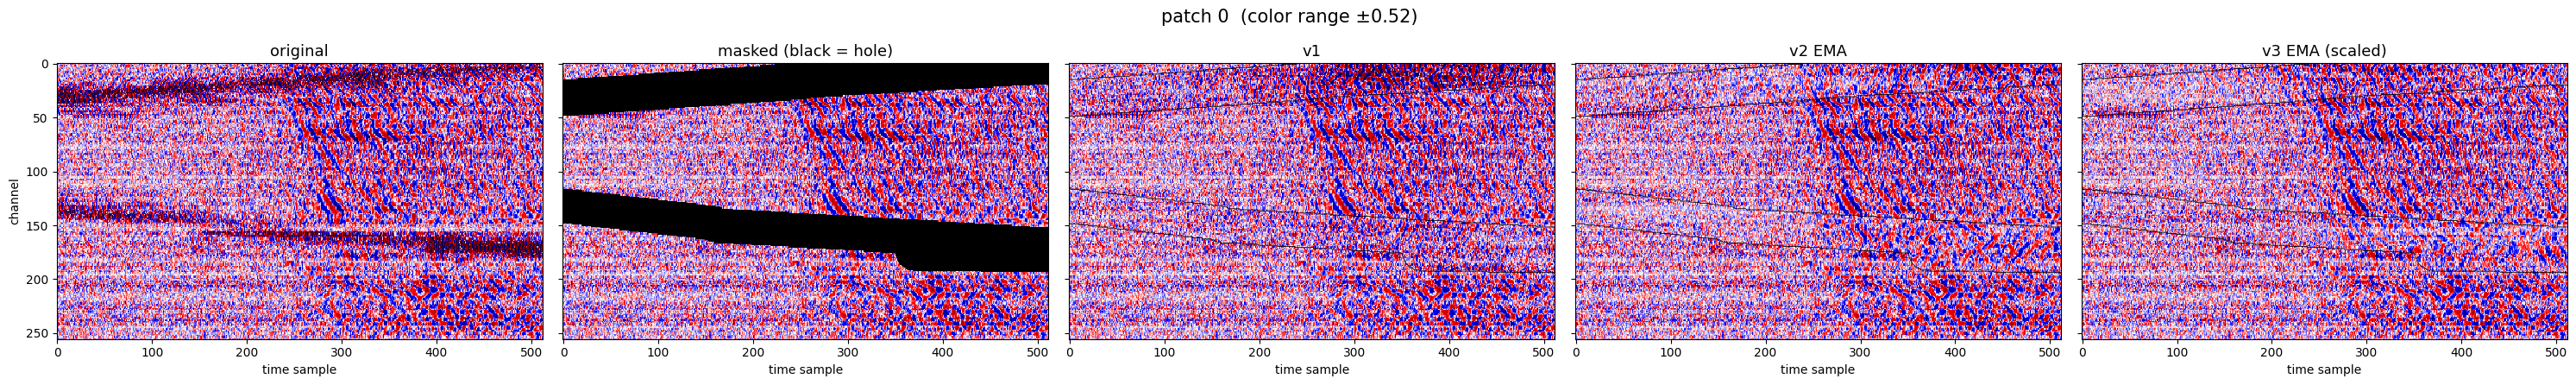

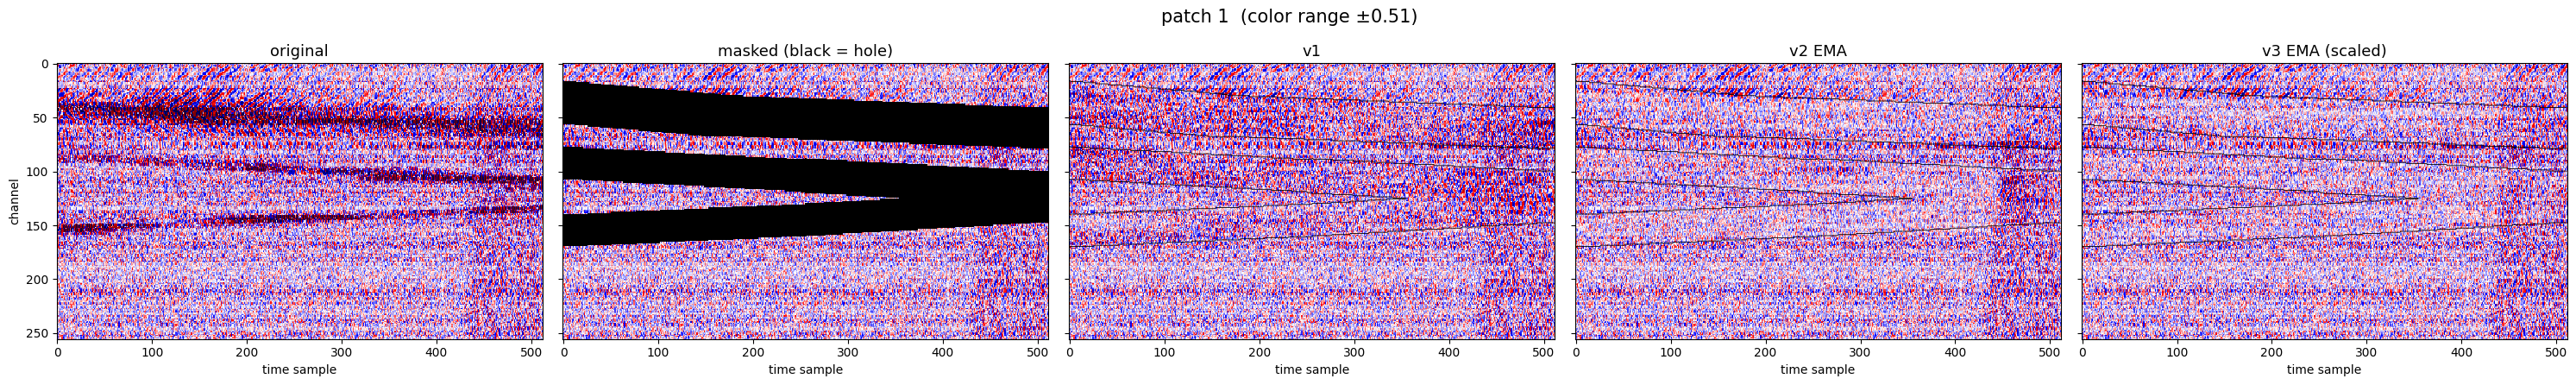

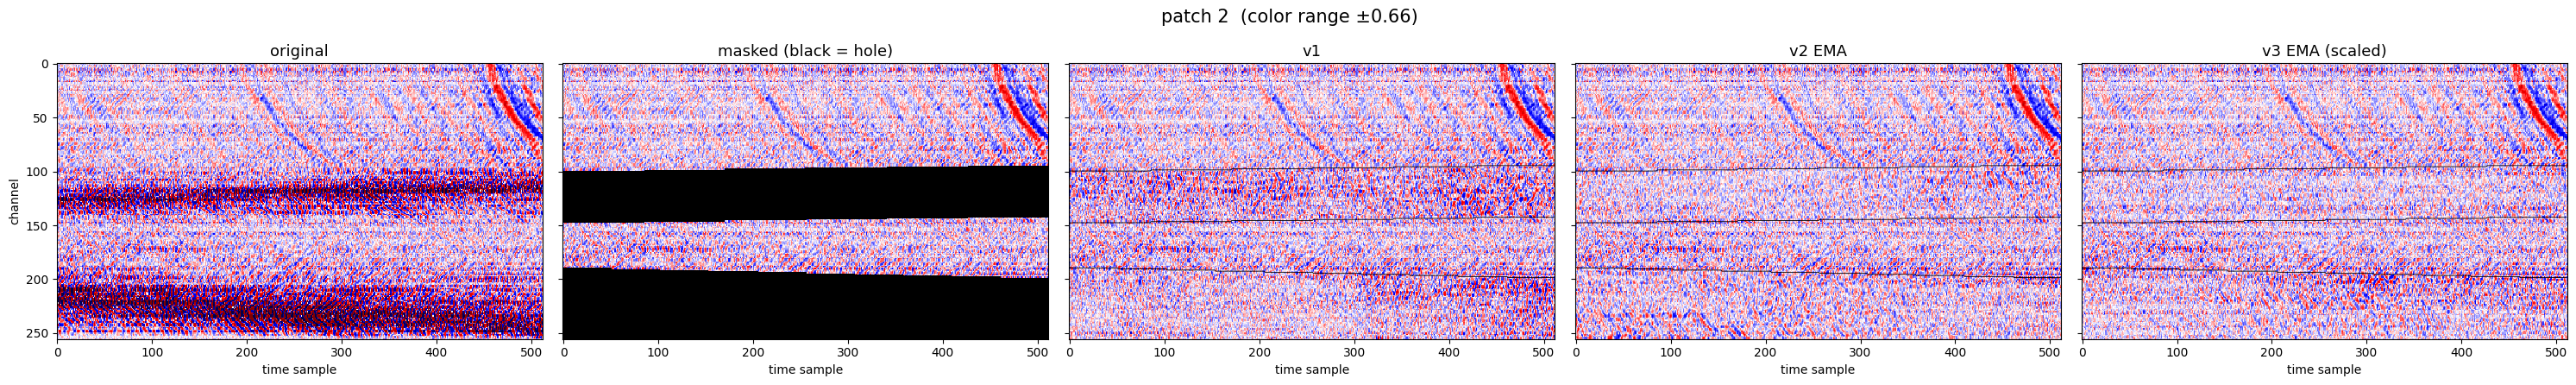

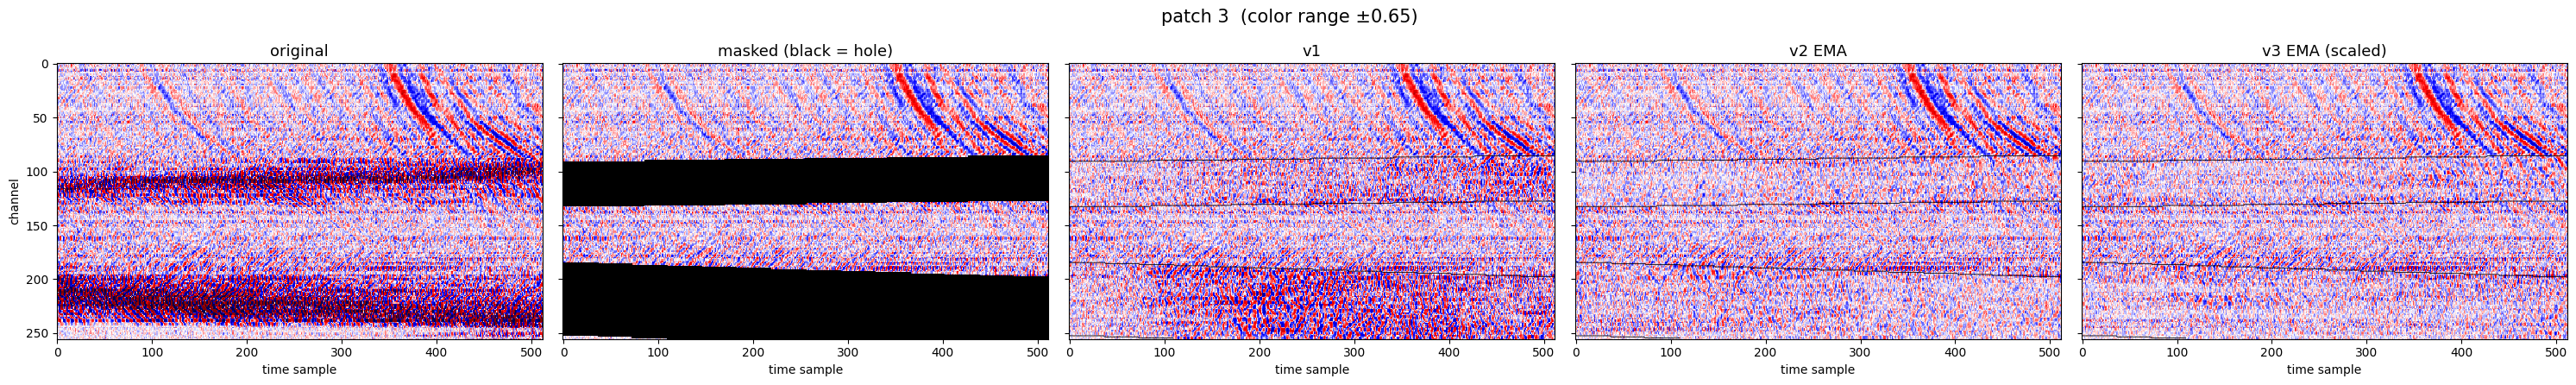

In [26]:
def show_row(k,i,zoom=None):
    """k = index in X, i = patch id. zoom = (c0,c1,t0,t1) shows only a section."""
    x=X[k,0].detach().cpu(); m=M[k,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")

    masked=x.clone(); masked[m==0]=float("nan")
    panels=[(x,"original"),(masked,"masked (black = hole)")]+[(r[k,0].detach().cpu(),n) for n,r in results.items()]

    fig,axes=plt.subplots(1,len(panels),figsize=(6*len(panels),4.5),sharey=True)
    for j,(a,(img,title)) in enumerate(zip(axes,panels)):
        a.imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if j>=2: a.contour(m,levels=[0.5],colors="k",linewidths=0.6)     # hole outline on results
        a.set_title(title,fontsize=13); a.set_xlabel("time sample")
        if zoom: a.set_ylim(zoom[1],zoom[0]); a.set_xlim(zoom[2],zoom[3])
    axes[0].set_ylabel("channel")
    fig.suptitle(f"patch {i}  (color range ±{w:.2f})",fontsize=15)
    plt.tight_layout(); plt.show()

for k,i in enumerate(patch_ids):
    show_row(k,i)